# 10 - Extensions

Goal: go beyond the paper with extra fast models, other ways of handling uneven classes, and a business cost view of the decision threshold.

Extends: paper Section 4.1. We left out permutation importance to keep the project small.

Needs: notebook 03 for the side-by-side chart, though it still runs without it. Writes results/extensions.csv.

Expected run time: about 1 minute with 10 repeats.

Status: executed

Repeats: 10 (the paper uses 100). Set N_REPEATS = 100 for final results.

## 1. Setup
We follow the paper's method: a 70/30 split, seeds 0, 1, 2 and so on, and oversampling on the train part only. Oversampling means copying rows of the smaller class until the two classes are equal. The two cost numbers are our own assumptions, and they should be changed to match a real business.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from utils import (COLOURS, METRICS, RESULT_DIR, SEED, add_balanced, get_metrics, load_data, make_inputs,
                   paired_test, save_results, set_style, show_table, split_data)

N_REPEATS = 10  # paper uses 100
set_style()

# Assumptions, change them.
COST_FP = 5   # false positive: a discount offered to someone who would not buy
COST_FN = 20  # false negative: a likely buyer who gets no offer and leaves

df = load_data()
X, y = make_inputs(df)

## 2. Extra baselines
We add logistic regression and gradient boosting, using the paper's method on oversampled data. Logistic regression is a simple straight-line model, so it is a good reference. Gradient boosting builds many small trees, each fixing the errors of the ones before it.

We report accuracy, TPR (the share of real buyers found), TNR (the share of non-buyers labelled correctly) and F1 (one score combining how many buyers are found with how many "buyer" guesses are right). The last two columns convert accuracy and F1 to a 50/50 test set, the basis the paper's figures appear to fit. Look at the F1 column first.

In [2]:
def make_extra(seed):
    """The two extra models."""
    return {
        "Logistic regression": LogisticRegression(max_iter=2000),
        "Gradient boosting": HistGradientBoostingClassifier(random_state=seed),
    }

rows = []
for repeat in range(N_REPEATS):
    X_tr, X_te, y_tr, y_te = split_data(X, y, seed=repeat, oversample=True)
    for name, model in make_extra(repeat).items():
        model.fit(X_tr, y_tr)
        rows.append({"model": name, "setting": "oversampled", "repeat": repeat,
                     **get_metrics(y_te, model.predict(X_te))})
extra = pd.DataFrame(rows)

# Put them next to the paper's models from notebook 03, if that notebook has been run.
path = f"{RESULT_DIR}/baselines.csv"
if os.path.exists(path):
    base = pd.read_csv(path)
    base = base[base["setting"] == "oversampled"]
    both = pd.concat([base, extra])
else:
    both = extra
table = add_balanced(both.groupby("model")[METRICS].mean()).sort_values("f1", ascending=False)
show_table(table, f"Oversampled setting, natural test set, {N_REPEATS} repeats",
           best=METRICS + ["accuracy_5050", "f1_5050"], digits=3)

,accuracy,tpr,tnr,f1,accuracy_5050,f1_5050
model,,,,,,
Gradient boosting,0.875,0.778,0.893,0.659,0.836,0.826
Random forest,0.899,0.621,0.950,0.655,0.785,0.743
SVM RBF,0.876,0.748,0.900,0.651,0.824,0.809
SVM linear,0.875,0.745,0.899,0.649,0.822,0.807
Logistic regression,0.847,0.752,0.864,0.603,0.808,0.796
C4.5,0.831,0.818,0.833,0.600,0.826,0.824


Gradient boosting has the highest natural-test F1 (0.659), and on the 50/50 basis it reaches 83.6% with F1 0.826. Random forest is next on natural-test F1 at 0.655. Logistic regression is weaker, at F1 0.603 and accuracy 84.7%, so models that can capture curved relations do add something.

## 3. Extra baselines on one chart
This chart shows natural-test accuracy and F1 for all models. Compare the F1 bars.

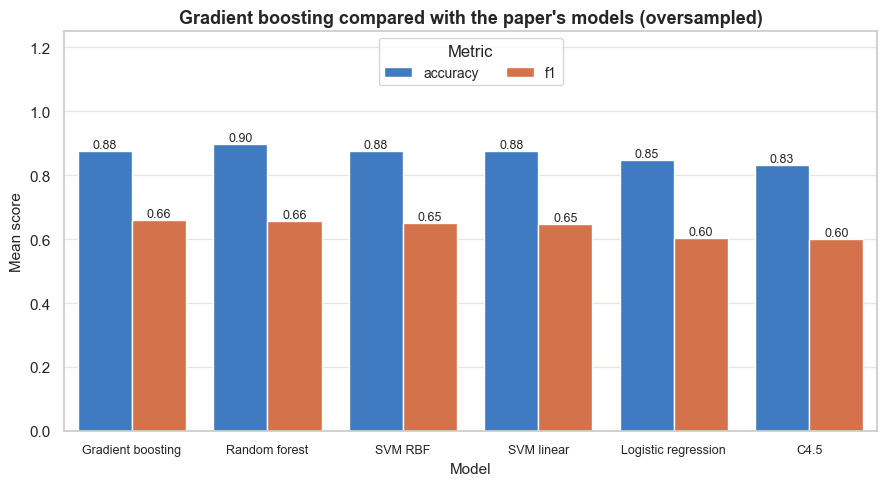

Gradient boosting vs random forest, F1: p = 0.3682 N.S.


In [3]:
order = table.index.tolist()
long = both.melt(id_vars=["model"], value_vars=["accuracy", "f1"], var_name="metric")
fig, ax = plt.subplots()
sns.barplot(data=long, x="model", y="value", hue="metric", order=order, errorbar=None,
            palette=COLOURS[:2], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9)
ax.set_title("Gradient boosting compared with the paper's models (oversampled)")
ax.set_xlabel("Model")
ax.set_ylabel("Mean score")
ax.set_ylim(0, 1.25)
ax.tick_params(axis="x", labelsize=9)
ax.legend(title="Metric", loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

scores = extra[extra["model"] == "Gradient boosting"].sort_values("repeat")
if os.path.exists(path):
    other = base[base["model"] == "Random forest"].sort_values("repeat")
    p, mark = paired_test(scores["f1"].values, other["f1"].values)
    print(f"Gradient boosting vs random forest, F1: p = {p:.4f} {mark}")

The F1 bars are all between 0.60 and 0.66, so the models are close. Gradient boosting's lead over random forest is not significant (p = 0.37), so it could be just chance. Random forest has the highest natural-test accuracy (0.899) because of its high TNR.

## 4. Ways of handling the imbalance
We use one fast model, gradient boosting, with four treatments of the train part. None trains on the data as it is. Random oversampling copies purchase rows, which is the paper's method. SMOTE creates new purchase rows between existing neighbouring rows. Class weight keeps the data but counts purchase rows more during training.

Limitation: SMOTE treats one-hot columns as ordinary numbers, so its new rows can contain fractional categories. SMOTENC handles categories properly, but we kept the simpler version.

Look at how TPR changes between treatments, and how little F1 changes.

In [4]:
rows = []
for repeat in range(N_REPEATS):
    X_tr, X_te, y_tr, y_te = split_data(X, y, seed=repeat)
    X_over, _, y_over, _ = split_data(X, y, seed=repeat, oversample=True)
    X_smote, y_smote = SMOTE(random_state=repeat).fit_resample(X_tr, y_tr)

    treatments = {
        "None": (X_tr, y_tr, {}),
        "Random oversampling": (X_over, y_over, {}),
        "SMOTE": (X_smote, y_smote, {}),
        "Class weight": (X_tr, y_tr, {"class_weight": "balanced"}),
    }
    for name, (X_fit, y_fit, options) in treatments.items():
        model = HistGradientBoostingClassifier(random_state=repeat, **options).fit(X_fit, y_fit)
        rows.append({"model": name, "setting": "gradient boosting", "repeat": repeat,
                     **get_metrics(y_te, model.predict(X_te))})
imb = pd.DataFrame(rows)
save_results(pd.concat([extra, imb]).to_dict("records"), "extensions")

table = imb.groupby("model")[METRICS].mean().sort_values("f1", ascending=False)
show_table(table, f"Imbalance treatments with gradient boosting, {N_REPEATS} repeats", best=METRICS, digits=3)

,accuracy,tpr,tnr,f1
model,,,,
SMOTE,0.898,0.664,0.940,0.667
Class weight,0.876,0.783,0.893,0.661
Random oversampling,0.875,0.778,0.893,0.659
None,0.901,0.589,0.958,0.648


F1 barely separates the four treatments (0.648 to 0.667). TPR is what really changes: 0.589 with no treatment, 0.664 with SMOTE, 0.778 with random oversampling and 0.783 with class weight.

This chart shows the same results, and the printed lines below it test SMOTE against random oversampling. A significant difference is one that is unlikely to be just chance.

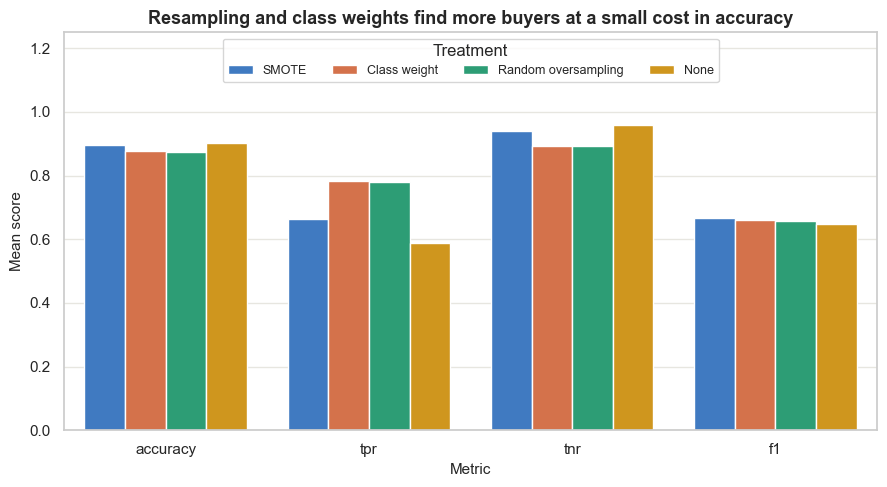

SMOTE vs random oversampling, accuracy: p = 0.0000 **
SMOTE vs random oversampling, tpr: p = 0.0000 **
SMOTE vs random oversampling, tnr: p = 0.0000 **
SMOTE vs random oversampling, f1: p = 0.0256 *


In [5]:
long = imb.melt(id_vars=["model"], value_vars=METRICS, var_name="metric")
fig, ax = plt.subplots()
sns.barplot(data=long, x="metric", y="value", hue="model", hue_order=table.index.tolist(),
            errorbar=None, palette=COLOURS[:4], ax=ax)
ax.set_title("Resampling and class weights find more buyers at a small cost in accuracy")
ax.set_xlabel("Metric")
ax.set_ylabel("Mean score")
ax.set_ylim(0, 1.25)
ax.legend(title="Treatment", loc="upper center", ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

a = imb[imb["model"] == "SMOTE"].sort_values("repeat")
b = imb[imb["model"] == "Random oversampling"].sort_values("repeat")
for metric in METRICS:
    p, mark = paired_test(a[metric].values, b[metric].values)
    print(f"SMOTE vs random oversampling, {metric}: p = {p:.4f} {mark}")

SMOTE has slightly higher F1 than random oversampling (0.667 against 0.659, p = 0.0256). It finds fewer buyers (TPR 0.664 against 0.778, p below 0.01) and has a higher TNR (0.940 against 0.893, p below 0.01). Class weight behaves almost the same as random oversampling, with TPR 0.783 and F1 0.661. So the choice depends on which kind of error costs more.

## 5. Decision threshold and business cost
A model gives a score, and we choose the cut-off, or threshold, above which we make an offer. We split the train part again: 75% to fit and 25% as validation to choose the threshold. Then we report on the untouched test set. We use one split (seed 42). The model is trained without oversampling, because the threshold itself handles the uneven classes.

A false positive means offering a discount to someone who would not buy. A false negative means missing a likely buyer. Total cost is COST_FP times the false positives plus COST_FN times the false negatives. We assume COST_FP = 5 and COST_FN = 20.

In [6]:
X_tr, X_te, y_tr, y_te = split_data(X, y, seed=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=SEED)
model = HistGradientBoostingClassifier(random_state=SEED).fit(X_fit, y_fit)
val_score = model.predict_proba(X_val)[:, 1]
test_score = model.predict_proba(X_te)[:, 1]

def total_cost(y_true, score, threshold):
    """Money lost at one threshold, using the assumed costs."""
    pred = (score > threshold).astype(int)
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    return COST_FP * fp + COST_FN * fn

thresholds = np.arange(0.01, 1.0, 0.01)
val_cost = np.array([total_cost(y_val.values, val_score, t) for t in thresholds])
test_cost = np.array([total_cost(y_te.values, test_score, t) for t in thresholds])
best_t = thresholds[val_cost.argmin()]  # chosen on validation only

This chart shows total test-set cost at every threshold, with the threshold chosen on validation and the default of 0.5. Look at how far the lowest point of the curve is from the 0.5 line.

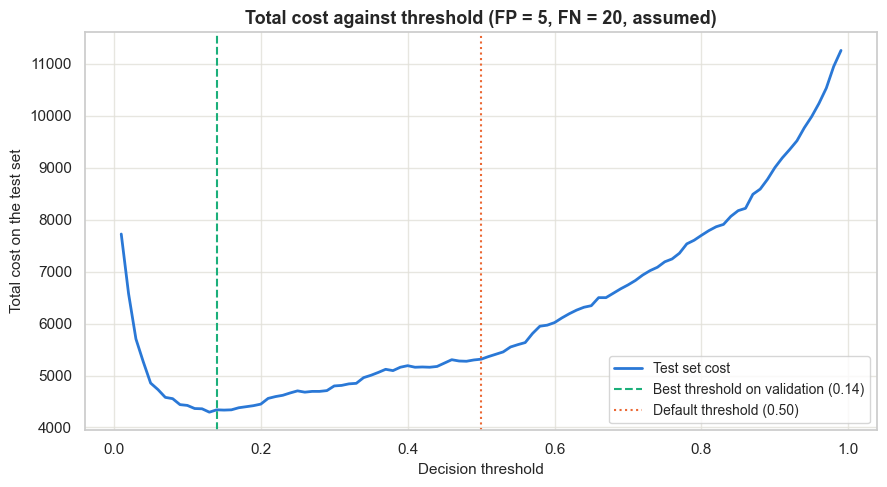

Saving against the default: 975.0 (18.3%)


,accuracy,tpr,tnr,f1,cost
Default 0.50,0.898,0.601,0.952,0.645,5315.000
Best 0.14,0.853,0.811,0.861,0.630,4340.000


In [7]:
fig, ax = plt.subplots()
ax.plot(thresholds, test_cost, color=COLOURS[0], linewidth=2, label="Test set cost")
ax.axvline(best_t, color=COLOURS[2], linestyle="--", label=f"Best threshold on validation ({best_t:.2f})")
ax.axvline(0.5, color=COLOURS[1], linestyle=":", label="Default threshold (0.50)")
ax.set_title(f"Total cost against threshold (FP = {COST_FP}, FN = {COST_FN}, assumed)")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Total cost on the test set")
ax.legend()
plt.tight_layout()
plt.show()

rows = {}
for label, t in [("Default 0.50", 0.5), (f"Best {best_t:.2f}", best_t)]:
    rows[label] = {**get_metrics(y_te, (test_score > t).astype(int)), "cost": total_cost(y_te.values, test_score, t)}
result = pd.DataFrame(rows).T
print("Saving against the default:", result["cost"].iloc[0] - result["cost"].iloc[1],
      f"({1 - result['cost'].iloc[1] / result['cost'].iloc[0]:.1%})")
show_table(result, "Test set results at the two thresholds", digits=3)

The validation set chooses a threshold of 0.14. On the test set, the cost falls from 5,315 at the default 0.5 to 4,340, a saving of 975 (18.3%). TPR rises from 0.601 to 0.811, while TNR falls from 0.952 to 0.861, accuracy from 0.898 to 0.853, and F1 from 0.645 to 0.630. So the cheapest choice has worse accuracy and F1.

## 6. Results at a glance
The paper does not run these experiments, so most rows have no paper value. Where one exists, the paper's model is shown on the 50/50 basis. Extra models use 10 repeats, and the threshold result uses one split.

| Result | Ours | Paper |
|---|---|---|
| Gradient boosting, accuracy % on the 50/50 basis | 83.6 | not run |
| Gradient boosting, F1 on the 50/50 basis | 0.826 | not run |
| C4.5, accuracy % on the 50/50 basis (for reference) | 82.6 | 82.34 |
| Logistic regression, F1 on the natural test set | 0.603 | not run |
| Random oversampling with gradient boosting, TPR | 0.778 | not run |
| SMOTE with gradient boosting, TPR | 0.664 | not run |
| Cost at threshold 0.50 | 5,315 | not run |
| Cost at threshold 0.14 | 4,340 | not run |

Gradient boosting is about as good as the best models we ran, at low effort. SMOTE gives a slightly higher F1 but finds fewer buyers than plain copying. The threshold has a large effect: with our assumed costs, moving it from 0.50 to 0.14 saves 18.3%.

## 7. Key takeaways
We ran 10 repeats for the extra models and one split for the threshold. Test sets keep the natural 15.5% purchase rate unless we say otherwise.

Gradient boosting has the highest F1 (0.659) of the non-neural models, but it is not significantly above random forest (0.655, p = 0.37). On the 50/50 basis it reaches 83.6% and F1 0.826. Logistic regression is weaker (F1 0.603, accuracy 84.7%), so non-linear models do add something.

SMOTE has slightly higher F1 than random oversampling (0.667 against 0.659), but finds fewer buyers (TPR 0.664 against 0.778) and has a higher TNR (0.940 against 0.893). Class weights behave like random oversampling (TPR 0.783, F1 0.661). With no treatment, TPR is 0.589 and F1 is 0.648.

With the assumed costs, the validation set picks a threshold of 0.14. The test cost falls from 5,315 to 4,340, a saving of 975 (18.3%). TPR rises from 0.601 to 0.811, while TNR falls from 0.952 to 0.861 and F1 falls from 0.645 to 0.630.

What this means for the business: the default 0.5 threshold is not automatically the best choice. If missing a buyer costs four times as much as a wasted offer, it pays to make offers much more freely, even though accuracy falls from 0.898 to 0.853. A shop should choose the threshold from its own costs. Our costs are assumptions, and this is one split. The cost model also ignores discounts given to visitors who would have bought anyway, so the real saving could be smaller.